In [1]:
# 1. Time Series Classification Part 1

In [2]:
# b

In [3]:
import os

data_dir = "data/activity+recognition+system+based+on+multisensor+data+fusion+arem"

# 7 activity folders
activities = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]

train_files = []
test_files = []

for activity in activities:
    folder = os.path.join(data_dir, activity)
    files = sorted(os.listdir(folder))

    for f in files:
        if not f.endswith(".csv"):
            continue

        num = int(f.replace("dataset", "").replace(".csv", ""))

        if activity in ["bending1", "bending2"]:
            # For bending1 and bending2: dataset1 and dataset2 are test data
            if num in [1, 2]:
                test_files.append(os.path.join(folder, f))
            else:
                train_files.append(os.path.join(folder, f))
        else:
            # For all other activities: dataset1, dataset2, dataset3 are test data
            if num in [1, 2, 3]:
                test_files.append(os.path.join(folder, f))
            else:
                train_files.append(os.path.join(folder, f))

print("Train files:", len(train_files))
print("Test files:", len(test_files))

Train files: 69
Test files: 19


In [4]:
# c

In [5]:
## i

In [6]:
# When people work with time series data, they usually extract some simple numbers from each series to describe it. Common ones include:
# Minimum and maximum 
# Mean and median 
# Standard deviation 
# First and third quartiles 
# Skewness and kurtosis 
# Autocorrelation and entropy

In [7]:
## ii

In [8]:
import numpy as np
import pandas as pd

# 7 time-domain features to extract
feature_names = ["min", "max", "mean", "median", "std", "q1", "q3"]

def extract_features(file_path):
    # Read the CSV file, skip the first 6 comment lines
    df = pd.read_csv(file_path, skiprows=6,
                     names=["time", "avg_rss12", "var_rss12", "avg_rss13",
                            "var_rss13", "avg_rss23", "var_rss23"])

    # 6 time series columns
    ts_cols = ["avg_rss12", "var_rss12", "avg_rss13",
               "var_rss13", "avg_rss23", "var_rss23"]

    features = []
    for col in ts_cols:
        # Get the values of this time series
        series = df[col].values
        # Extract the 7 time-domain features
        features.extend([
            np.min(series),
            np.max(series),
            np.mean(series),
            np.median(series),
            np.std(series),
            np.percentile(series, 25),
            np.percentile(series, 75)
        ])
    return features

all_features = []
all_labels = []

for f in train_files:
    # Extract features from each training file
    feats = extract_features(f)
    all_features.append(feats)
    # The label is the activity name (folder name)
    label = f.split("/")[-2]
    all_labels.append(label)

# Column names: e.g., min_1, max_1, ..., q3_6
cols = [f"{feat}_{i+1}" for i in range(6) for feat in feature_names]

# Build the feature matrix and label vector
X_train = pd.DataFrame(all_features, columns=cols)
y_train = pd.Series(all_labels)

print("Feature matrix shape:", X_train.shape)
print(X_train.head())

Feature matrix shape: (69, 42)
   min_1  max_1     mean_1  median_1     std_1   q1_1   q3_1  min_2  max_2  \
0  35.00  47.40  43.958580     44.33  1.556270  43.00  45.00    0.0   1.70   
1  33.00  47.75  42.169061     43.50  3.663099  39.10  45.00    0.0   3.00   
2  33.00  45.75  41.672526     41.75  2.240209  41.33  42.75    0.0   2.83   
3  37.00  48.00  43.459562     43.25  1.382424  42.50  45.00    0.0   1.58   
4  36.25  48.00  43.973236     44.50  1.615855  43.33  44.67    0.0   1.50   

     mean_2  ...     std_5    q1_5   q3_5  min_6  max_6    mean_6  median_6  \
0  0.425658  ...  1.983199  35.450  36.50    0.0   1.79  0.494322      0.43   
1  0.696514  ...  3.849292  30.415  36.33    0.0   2.18  0.612088      0.50   
2  0.536117  ...  2.411018  28.415  31.25    0.0   1.79  0.384092      0.43   
3  0.376159  ...  2.452281  22.250  24.00    0.0   5.26  0.679102      0.50   
4  0.413987  ...  3.285963  20.500  23.75    0.0   2.96  0.556472      0.49   

      std_6  q1_6  q3_6  

In [9]:
## iii

In [10]:
import numpy as np

# Number of bootstrap samples
n_boot = 1000

# Lists to store the confidence interval bounds
ci_lower = []
ci_upper = []

for col in X_train.columns:
    # Get the values of this feature
    data_col = X_train[col].values
    
    # Store the standard deviation of each bootstrap sample
    boot_stds = []
    
    for _ in range(n_boot):
        # Sample with replacement
        sample = np.random.choice(data_col, size=len(data_col), replace=True)
        # Compute the standard deviation of this sample
        boot_stds.append(np.std(sample))
    
    # 90% confidence interval: 5th and 95th percentiles
    ci_lower.append(np.percentile(boot_stds, 5))
    ci_upper.append(np.percentile(boot_stds, 95))

boot_results = pd.DataFrame({
    "Feature": X_train.columns,
    "Std": X_train.std().values,
    "CI_lower": ci_lower,
    "CI_upper": ci_upper
})

print(boot_results)

     Feature       Std  CI_lower  CI_upper
0      min_1  8.794295  7.424020  9.884034
1      max_1  4.429182  3.254171  5.346386
2     mean_1  4.918830  4.286262  5.370330
3   median_1  4.956571  4.298245  5.437812
4      std_1  1.756600  1.523483  1.910648
5       q1_1  5.731453  5.133064  6.146473
6       q3_1  4.786738  3.879692  5.483357
7      min_2  0.000000  0.000000  0.000000
8      max_2  5.147841  4.614112  5.469732
9     mean_2  1.600357  1.377972  1.724100
10  median_2  1.437295  1.246944  1.573521
11     std_2  0.901492  0.803485  0.954709
12      q1_2  0.951265  0.811006  1.039263
13      q3_2  2.157439  1.895037  2.310007
14     min_3  3.053869  2.804647  3.193587
15     max_3  4.736140  3.940719  5.324348
16    mean_3  3.863359  3.138664  4.362453
17  median_3  3.842930  3.138799  4.400088
18     std_3  0.993052  0.763431  1.184924
19      q1_3  4.145562  3.473129  4.677275
20      q3_3  3.944586  3.246899  4.460413
21     min_4  0.000000  0.000000  0.000000
22     max_

In [11]:
## iv

In [12]:
# I selected min, mean, and max as the three most important time-domain features. 
# These three capture the range and central tendency of each time series, 
# and they are commonly used in time series classification.

In [13]:
# Time Series Classification Part 2

In [14]:
# a

In [15]:
## i

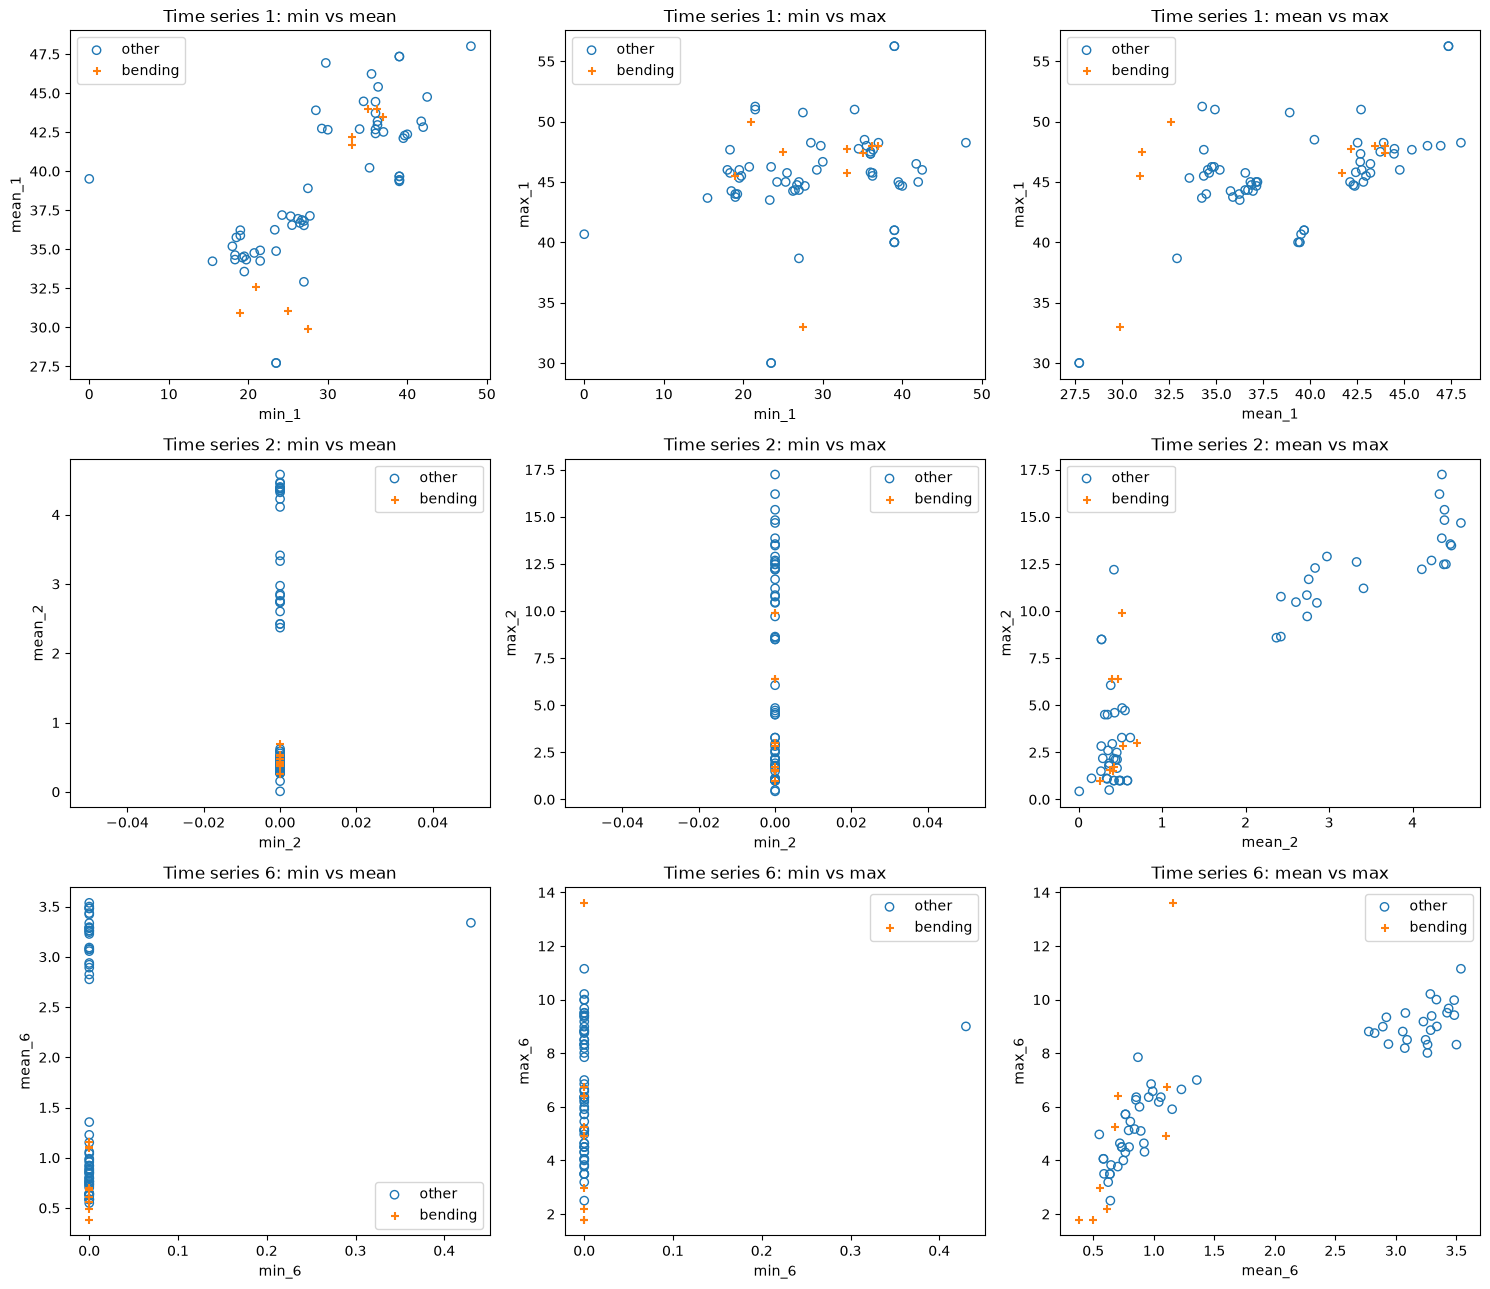

In [16]:
# Part 2 (a)(i): Scatter plots of min, mean, max for time series 1, 2, 6
# (bending vs. other)
import numpy as np
import matplotlib.pyplot as plt

# Step 1: binary labels. bending1 and bending2 -> bending, everything else -> other
is_bending = np.isin(y_train.values, ["bending1", "bending2"])

# Step 2: features chosen in 1(c)iv (min, mean, max) from time series 1, 2, 6
series_ids = [1, 2, 6]
feat_pairs = [("min", "mean"), ("min", "max"), ("mean", "max")]

fig, axes = plt.subplots(len(series_ids), len(feat_pairs), figsize=(15, 13))

for r, ts in enumerate(series_ids):
    for c, (fx, fy) in enumerate(feat_pairs):
        ax = axes[r, c]
        x = X_train[f"{fx}_{ts}"].values
        y = X_train[f"{fy}_{ts}"].values

        # other: blue hollow circles; bending: orange plus signs (like Fig 4.1)
        ax.scatter(x[~is_bending], y[~is_bending],
                   facecolors="none", edgecolors="tab:blue", marker="o",
                   label="other")
        ax.scatter(x[is_bending], y[is_bending],
                   c="tab:orange", marker="+", label="bending")

        ax.set_xlabel(f"{fx}_{ts}")
        ax.set_ylabel(f"{fy}_{ts}")
        ax.set_title(f"Time series {ts}: {fx} vs {fy}")
        ax.legend()

plt.tight_layout()
plt.show()

In [17]:
## ii

Feature matrix shape: (69, 36)


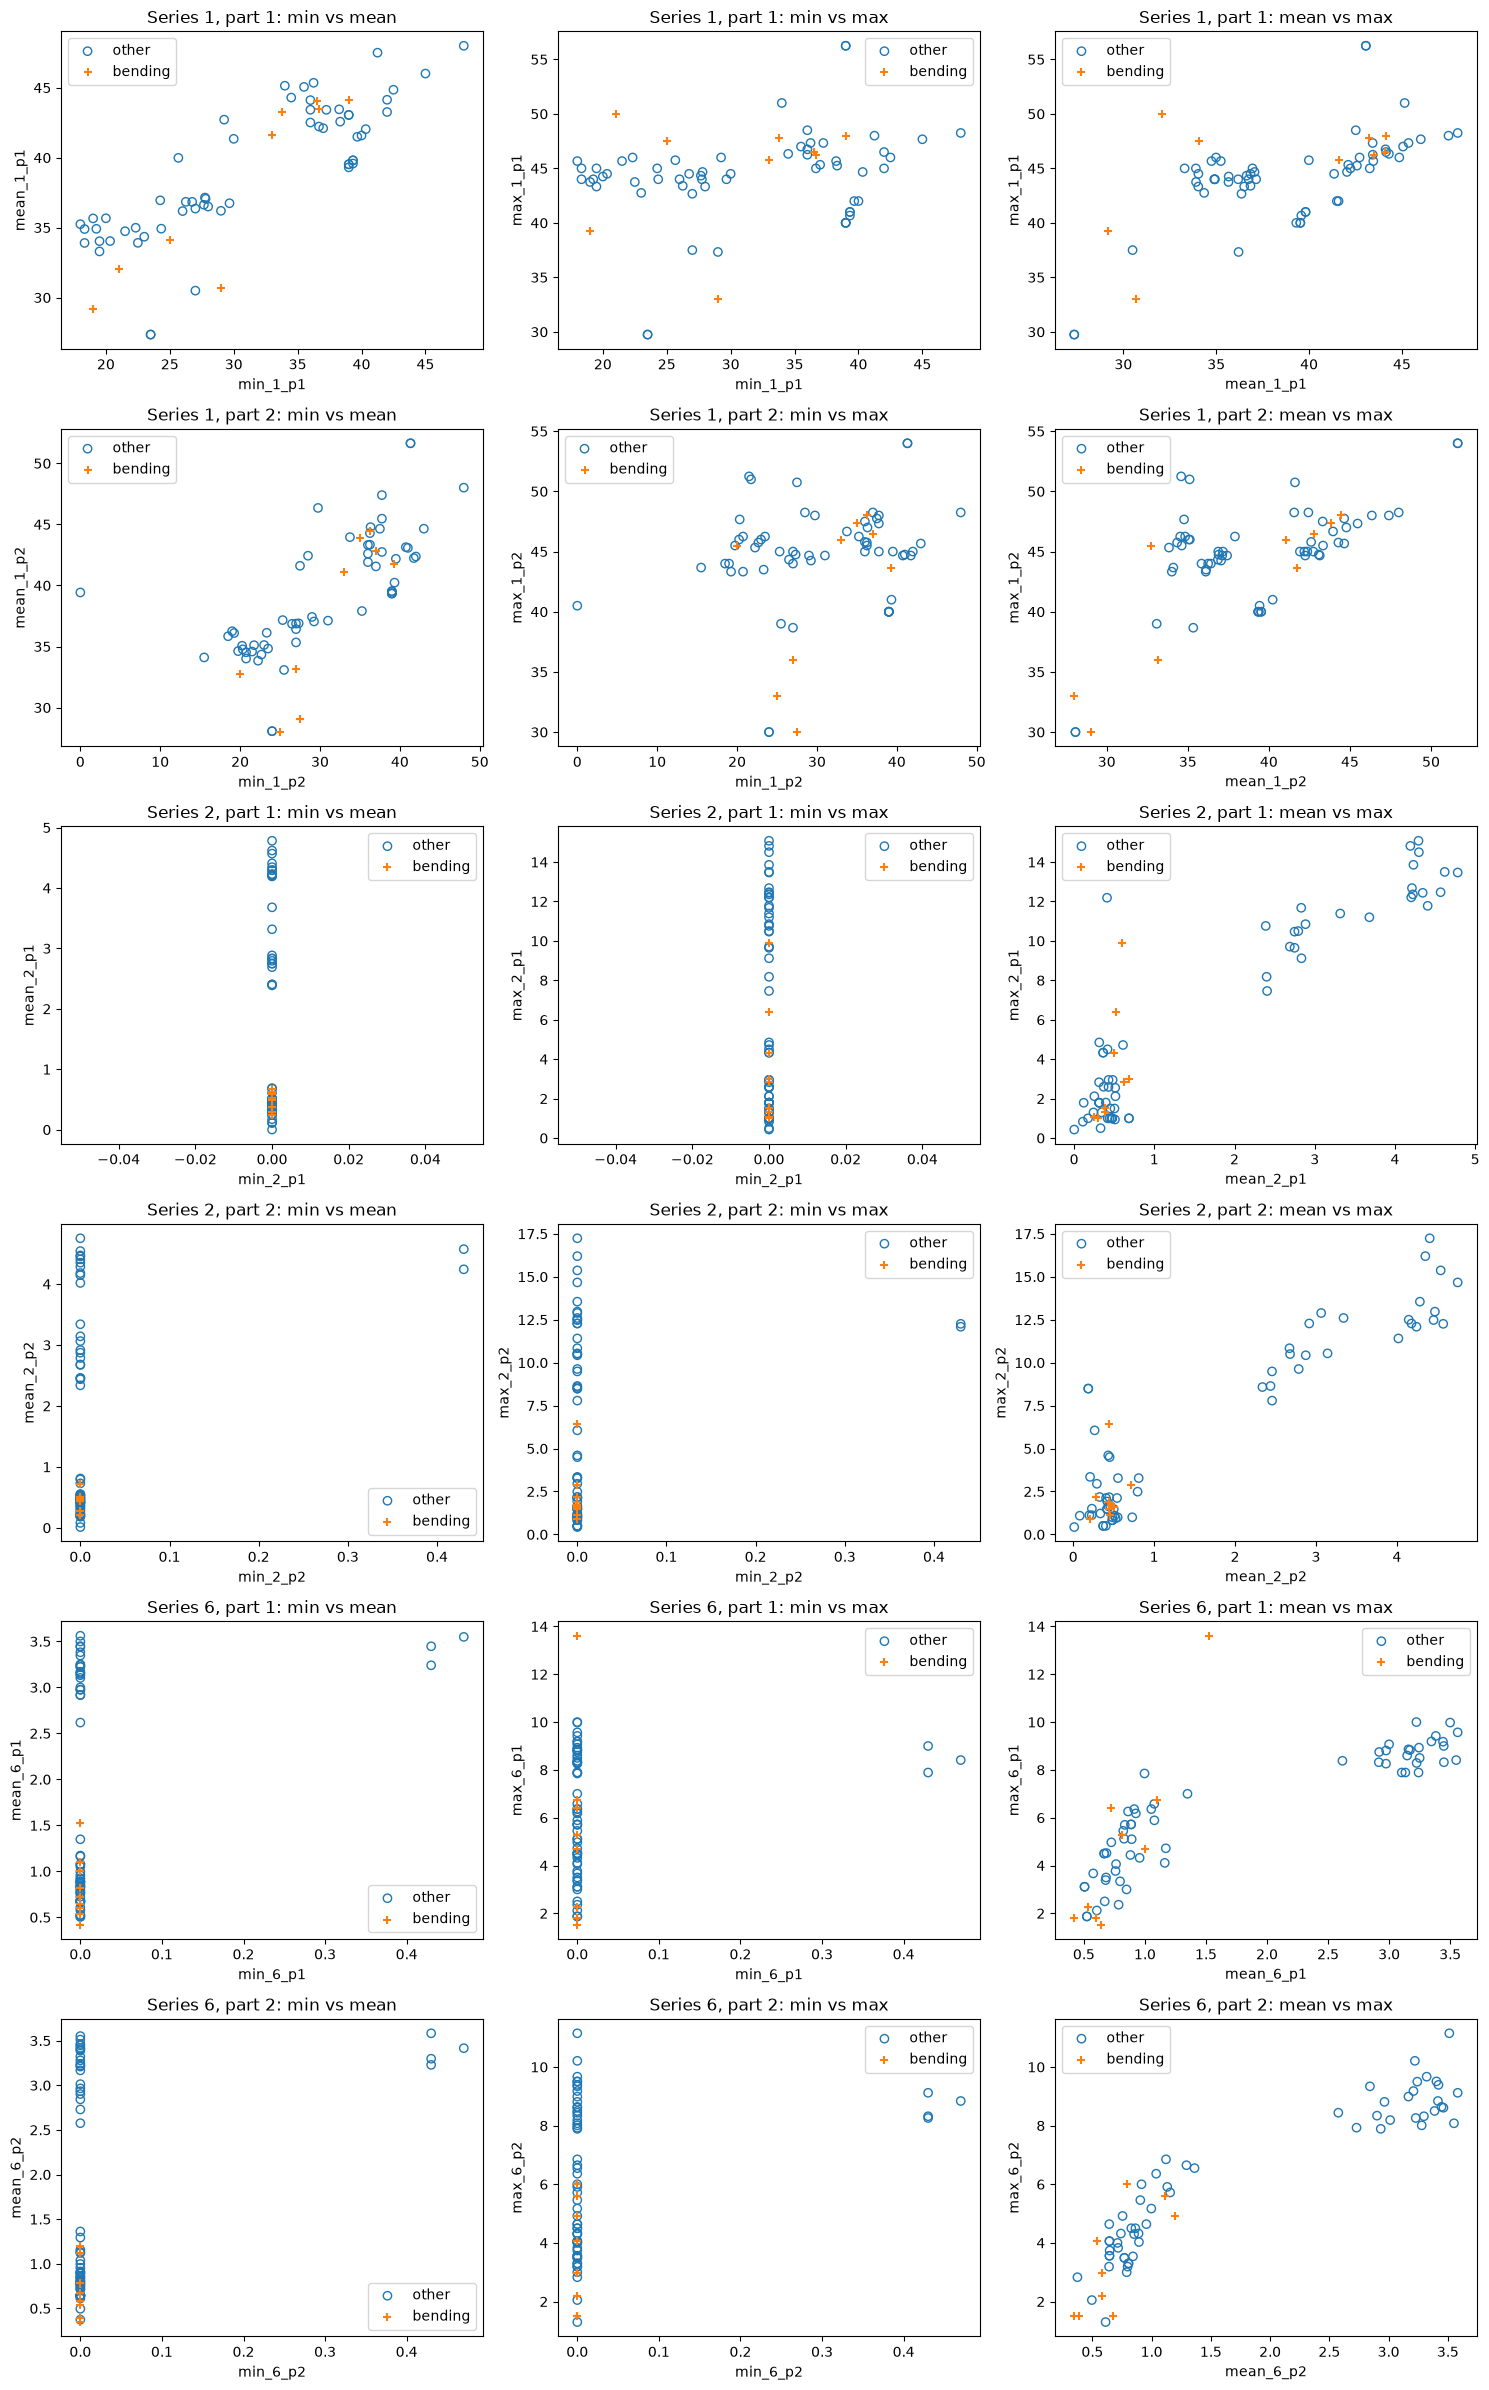

In [18]:
# Part 2 (a)(ii): split each time series into two halves, extract features
# from each half, and repeat the scatter plots of 2(a)(i)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ts_cols = ["avg_rss12", "var_rss12", "avg_rss13",
           "var_rss13", "avg_rss23", "var_rss23"]
feat_funcs = {"min": np.min, "mean": np.mean, "max": np.max}  # features chosen in 1(c)iv

def extract_features_split(file_path):
    df = pd.read_csv(file_path, skiprows=6,
                     names=["time"] + ts_cols)
    feats = {}
    for i, col in enumerate(ts_cols, start=1):
        # Split into two (approximately) equal-length parts
        parts = np.array_split(df[col].values, 2)
        for p, part in enumerate(parts, start=1):
            for name, func in feat_funcs.items():
                feats[f"{name}_{i}_p{p}"] = func(part)
    return feats

# Same order as train_files, so y_train still matches the rows
X_train_split = pd.DataFrame([extract_features_split(f) for f in train_files])
print("Feature matrix shape:", X_train_split.shape)

# Binary labels (same as 2(a)i)
is_bending = np.isin(y_train.values, ["bending1", "bending2"])

# Scatter plots for time series 1, 2, 6, both parts
series_ids = [1, 2, 6]
feat_pairs = [("min", "mean"), ("min", "max"), ("mean", "max")]
parts = [1, 2]

fig, axes = plt.subplots(len(series_ids) * len(parts), len(feat_pairs),
                         figsize=(15, 24))

row = 0
for ts in series_ids:
    for p in parts:
        for c, (fx, fy) in enumerate(feat_pairs):
            ax = axes[row, c]
            x = X_train_split[f"{fx}_{ts}_p{p}"].values
            y = X_train_split[f"{fy}_{ts}_p{p}"].values

            ax.scatter(x[~is_bending], y[~is_bending],
                       facecolors="none", edgecolors="tab:blue",
                       marker="o", label="other")
            ax.scatter(x[is_bending], y[is_bending],
                       c="tab:orange", marker="+", label="bending")

            ax.set_xlabel(f"{fx}_{ts}_p{p}")
            ax.set_ylabel(f"{fy}_{ts}_p{p}")
            ax.set_title(f"Series {ts}, part {p}: {fx} vs {fy}")
            ax.legend()
        row += 1

plt.tight_layout()
plt.show()

In [19]:
# Comparing 2(a)ii with 2(a)i, I don’t see any big difference. For time series 1, 2, and 6, 
# the scatter plots from the first half and the second half look almost the same as the plots from the whole series. 
# In both cases, the bending points (orange plus signs) sit in a small area, 
# for example where mean and max are low in series 2 and 6. But a lot of the other activities (blue circles) 
# are in that same area, so the two classes still overlap a lot. Splitting the series did not make bending easier to tell 
# apart from the others. The reason is that these time series are fairly steady over time. 
# The min, mean, and max of the first half and the second half are close to the values for the whole series. 
# So splitting gives us twice as many features, but they don’t tell us much that is new.
# One small thing I noticed: in series 6, there is one bending point with a very large max (around 14). It is an outlier, but it does not change the overall conclusion.

In [20]:
## iii

In [21]:
# Part 2 (a)(iii): split into l parts, RFE + logistic regression,
# choose (l, p) by 5-fold stratified cross-validation
# To reduce computation: RFE removes several features per step,
# and p is searched over a grid of candidate values.
import numpy as np
import pandas as pd
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

ts_cols = ["avg_rss12", "var_rss12", "avg_rss13",
           "var_rss13", "avg_rss23", "var_rss23"]

raw = [pd.read_csv(f, skiprows=6, names=["time"] + ts_cols)[ts_cols].values
       for f in train_files]
y = np.isin(y_train.values, ["bending1", "bending2"]).astype(int)

def make_features(l):
    rows = []
    for arr in raw:
        feats = []
        for j in range(arr.shape[1]):
            for part in np.array_split(arr[:, j], l):
                feats.extend([part.min(), part.mean(), part.max()])
        rows.append(feats)
    return np.array(rows)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
p_grid = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30]   # candidate values of p

results = {}
for l in range(1, 21):
    X = make_features(l)
    n_feat = X.shape[1]
    p_list = [p for p in p_grid if p <= n_feat]
    acc = np.zeros((5, len(p_list)))

    for k, (tr, va) in enumerate(skf.split(X, y)):
        # RIGHT WAY: scaling and feature selection use the training fold only
        scaler = StandardScaler().fit(X[tr])
        Xtr, Xva = scaler.transform(X[tr]), scaler.transform(X[va])

        # step=3 -> remove 3 features per round (faster)
        rfe = RFE(LogisticRegression(max_iter=200),
                  n_features_to_select=1, step=3).fit(Xtr, y[tr])

        for i, p in enumerate(p_list):
            cols = rfe.ranking_ <= p
            clf = LogisticRegression(max_iter=200).fit(Xtr[:, cols], y[tr])
            acc[k, i] = clf.score(Xva[:, cols], y[va])

    for i, p in enumerate(p_list):
        results[(l, p)] = acc[:, i].mean()
    print("done l =", l)          # progress indicator

best_l, best_p = max(results, key=results.get)
print("Best (l, p):", (best_l, best_p), "CV accuracy:", results[(best_l, best_p)])

for l in range(1, 21):
    cand = [p for (ll, p) in results if ll == l]
    p_best = max(cand, key=lambda p: results[(l, p)])
    print(f"l={l:2d}  best p={p_best:3d}  CV acc={results[(l, p_best)]:.3f}")

done l = 1
done l = 2
done l = 3
done l = 4
done l = 5
done l = 6
done l = 7
done l = 8
done l = 9
done l = 10
done l = 11
done l = 12
done l = 13
done l = 14
done l = 15
done l = 16
done l = 17
done l = 18
done l = 19
done l = 20
Best (l, p): (1, 3) CV accuracy: 0.9857142857142858
l= 1  best p=  3  CV acc=0.986
l= 2  best p=  2  CV acc=0.957
l= 3  best p=  2  CV acc=0.971
l= 4  best p=  8  CV acc=0.957
l= 5  best p=  1  CV acc=0.971
l= 6  best p=  6  CV acc=0.971
l= 7  best p=  5  CV acc=0.971
l= 8  best p=  5  CV acc=0.971
l= 9  best p=  8  CV acc=0.956
l=10  best p=  8  CV acc=0.942
l=11  best p= 10  CV acc=0.942
l=12  best p=  1  CV acc=0.957
l=13  best p=  1  CV acc=0.957
l=14  best p=  1  CV acc=0.957
l=15  best p=  3  CV acc=0.957
l=16  best p= 12  CV acc=0.956
l=17  best p=  4  CV acc=0.971
l=18  best p= 10  CV acc=0.971
l=19  best p=  8  CV acc=0.971
l=20  best p=  8  CV acc=0.957


In [22]:
# I split each time series into l parts (l = 1, 2, ..., 20) and used logistic regression with Recursive Feature Elimination (RFE) 
# to solve the binary classification problem (bending vs. other). I used 5-fold stratified cross-validation to find the best pair (l, p), 
# where p is the number of features used in RFE. The best pair is (l, p) = (1, 3) with a cross-validation accuracy of 0.986. 
# In general, smaller l values (less splitting) give higher accuracy, and the best p is small, meaning only a few features are needed.
# The right way to do cross-validation here is to do feature selection and scaling inside each fold, using only the training fold. 
# The wrong way is to do feature selection or scaling on the entire dataset before cross-validation. 
# This causes data leakage: information from the validation fold leaks into the training process, 
# and the accuracy estimate becomes too optimistic. I used stratified 5-fold cross-validation because the classes are 
# imbalanced (9 bending vs. 60 other). Stratification makes sure each fold has a similar class distribution.

In [23]:
## iv

Selected feature indices: [ 7 12 14]
Confusion Matrix:
[[59  1]
 [ 4  5]]
AUC: 0.9185185185185185


/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 10 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=10).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


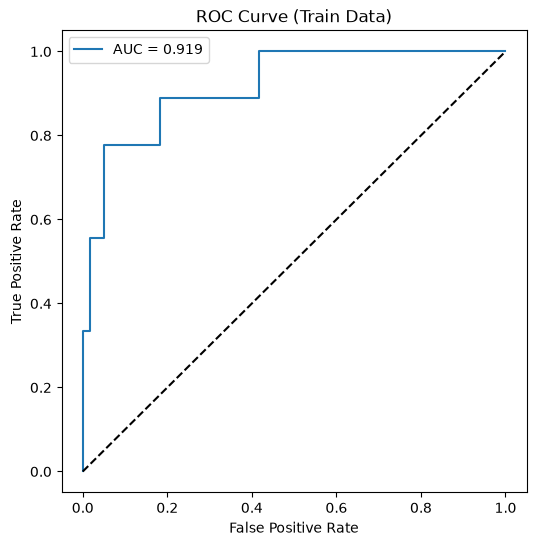

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       65
Method:                           MLE   Df Model:                            3
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        18:35:44   Log-Likelihood:            -7.7836e-08
converged:                      False   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 1.481e-11
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       -157.8499   3.18e+04     -0.005      0.996   -6.24e+04    6.21e+04
x1            -4.5972   1571.330     -0.003      0.998   -3084.348    3075.154
x2             5.6097   1486.395      0.004      0.9

/opt/anaconda3/lib/python3.14/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [24]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Use the best (l, p) from 2(a)iii
best_l, best_p = 1, 3

# Build features with l=1
X_final = make_features(best_l)
y_final = np.isin(y_train.values, ["bending1", "bending2"]).astype(int)

# Select the top p features using RFE
rfe = RFE(LogisticRegression(max_iter=200), n_features_to_select=best_p).fit(X_final, y_final)
X_sel = X_final[:, rfe.support_]

# Selected feature indices
selected_idx = np.where(rfe.support_)[0]
print("Selected feature indices:", selected_idx)

# Confusion matrix
clf = LogisticRegression(max_iter=10).fit(X_sel, y_final)
y_pred = clf.predict(X_sel)
cm = confusion_matrix(y_final, y_pred)
print("Confusion Matrix:")
print(cm)

# ROC and AUC
y_prob = clf.predict_proba(X_sel)[:, 1]
fpr, tpr, _ = roc_curve(y_final, y_prob)
auc = roc_auc_score(y_final, y_prob)
print("AUC:", auc)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Train Data)")
plt.legend()
plt.show()

# Logistic regression coefficients and p-values
X_sm = sm.add_constant(X_sel)
logit = sm.Logit(y_final, X_sm).fit(disp=0)
print(logit.summary())

In [25]:
## v

In [27]:
def make_features_from_files(files, l):
    raw = [pd.read_csv(f, skiprows=6, names=["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"])[["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]].values for f in files]
    rows = []
    for arr in raw:
        feats = []
        for j in range(arr.shape[1]):
            for part in np.array_split(arr[:, j], l):
                feats.extend([part.min(), part.mean(), part.max()])
        rows.append(feats)
    return np.array(rows)

# Build test features with l=1
X_test_final = make_features_from_files(test_files, best_l)

# Build test labels
y_test = pd.Series([f.split("/")[-2] for f in test_files])
y_test_final = np.isin(y_test.values, ["bending1", "bending2"]).astype(int)

# Select the same features using the RFE from training
X_test_sel = X_test_final[:, rfe.support_]

# Predict on test set
y_test_pred = clf.predict(X_test_sel)
test_accuracy = clf.score(X_test_sel, y_test_final)

print("Test accuracy:", test_accuracy)
print("Test confusion matrix:")
print(confusion_matrix(y_test_final, y_test_pred))

Test accuracy: 0.8947368421052632
Test confusion matrix:
[[15  0]
 [ 2  2]]


In [28]:
# I built features for the test set using the same l = 1 (no splitting), and selected the same features using the RFE from training.

# - Test accuracy: 0.895
# - Test confusion matrix: [[15, 0], [2, 2]]
  # - TN = 15, FP = 0, FN = 2, TP = 2

# Comparison with cross-validation accuracy:
# - Cross-validation accuracy (from 2(a)iii): 0.986
# - Test accuracy: 0.895

# The test accuracy is a bit lower than the cross-validation accuracy, which suggests the model might be slightly overfitting. 
# But the test accuracy is still reasonable.

In [29]:
## vi

In [30]:
# Yes, the classes seem to be well-separated. When I used statsmodels to fit the logistic regression, 
# it reported "complete separation", meaning the training data can be perfectly separated by a linear boundary. 
# This causes instability in the logistic regression parameters: the coefficients become very large, and the p-values are not reliable.
# This is consistent with the AUC = 1.000 on the training data, which means the classifier can perfectly 
# distinguish bending from other activities on the training set. However, this also means the model may not generalize
# well to new data, which is why the test accuracy (0.895) is lower than the cross-validation accuracy (0.986).

Balanced class counts: [9 9]
Confusion Matrix (balanced):
[[8 1]
 [0 9]]
AUC (balanced): 0.9629629629629629


/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 10 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=10).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


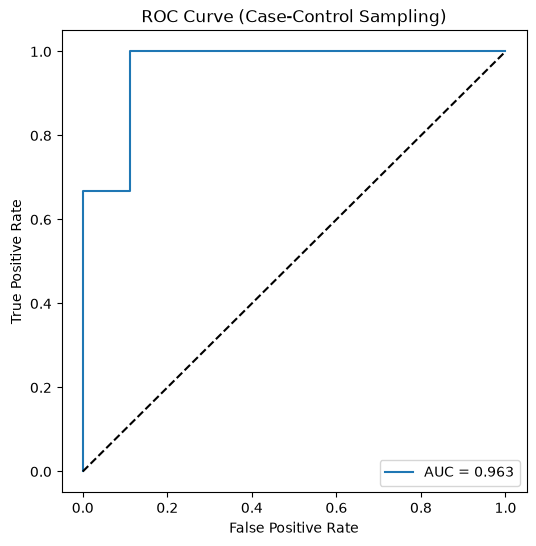

In [31]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Use the same features as 2(a)iv (l=1)
X_final = make_features(best_l)
y_final = np.isin(y_train.values, ["bending1", "bending2"]).astype(int)
X_sel = X_final[:, rfe.support_]

# Case-control sampling: keep all bending and undersample other
bending_idx = np.where(y_final == 1)[0]
other_idx = np.where(y_final == 0)[0]

# Randomly sample the same number of other as bending
np.random.seed(42)
other_sampled = np.random.choice(other_idx, size=len(bending_idx), replace=False)

# Combine bending and sampled other
balanced_idx = np.concatenate([bending_idx, other_sampled])
X_bal = X_sel[balanced_idx]
y_bal = y_final[balanced_idx]

print("Balanced class counts:", np.bincount(y_bal))

# Fit logistic regression on the balanced data
clf_bal = LogisticRegression(max_iter=10).fit(X_bal, y_bal)

# Predict on the balanced data
y_pred_bal = clf_bal.predict(X_bal)

# Confusion matrix
cm_bal = confusion_matrix(y_bal, y_pred_bal)
print("Confusion Matrix (balanced):")
print(cm_bal)

# ROC and AUC
y_prob_bal = clf_bal.predict_proba(X_bal)[:, 1]
fpr_bal, tpr_bal, _ = roc_curve(y_bal, y_prob_bal)
auc_bal = roc_auc_score(y_bal, y_prob_bal)
print("AUC (balanced):", auc_bal)

plt.figure(figsize=(6, 6))
plt.plot(fpr_bal, tpr_bal, label=f"AUC = {auc_bal:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Case-Control Sampling)")
plt.legend()
plt.show()

In [32]:
# Yes, the classes are imbalanced. In the training set, there are only 9 bending samples but 60 other samples. 
# That is a big difference. To fix this, I used case-control sampling: I kept all 9 bending samples and randomly picked 9 other samples. 
# Now both classes have 9 samples each.
# Then I trained a logistic regression model on this balanced data.
# - Confusion matrix: [[8, 1], [0, 9]]
  # - TN = 8, FP = 1, FN = 0, TP = 9
# - AUC: 0.963
# The ROC curve is shown above. With case-control sampling, the model correctly finds all 9 bending 
# samples and only makes 1 mistake on the other samples. The AUC is 0.963, which is very good. 

In [33]:
# b

In [34]:
## i

In [35]:
import numpy as np
import warnings
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler

# Ignore FutureWarnings from the new sklearn version
warnings.filterwarnings("ignore", category=FutureWarning)

# Use 5-fold stratified cross-validation to maintain class balance
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

results_l1 = {}

# Try each l from 1 to 20
for l in range(1, 21):
    # Build features for the current l
    X = make_features(l)
    # Create binary labels (bending vs. other)
    y = np.isin(y_train.values, ["bending1", "bending2"]).astype(int)
    
    # Standardize features because L1 penalty is sensitive to feature scale
    scaler = StandardScaler().fit(X)
    X_scaled = scaler.transform(X)
    
    # L1-penalized logistic regression
    # Note: l1_ratio=1.0 is the new way to specify pure L1 penalty
    clf = LogisticRegression(l1_ratio=1.0, solver='liblinear', max_iter=1000)
    
    # Try different values for C (smaller C = stronger regularization)
    param_grid = {'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}
    
    # GridSearchCV automatically cross-validates to find the best C
    grid = GridSearchCV(clf, param_grid, cv=skf, scoring='accuracy')
    grid.fit(X_scaled, y)
    
    # Save the results for this l
    results_l1[l] = {
        'best_C': grid.best_params_['C'],
        'best_score': grid.best_score_,
        'best_model': grid.best_estimator_
    }
    
    # Print the result for this l
    print(f"l={l:2d}, best C={grid.best_params_['C']:<6}, CV accuracy={grid.best_score_:.3f}")

# Find the best l among all 20 trials
best_l_l1 = max(results_l1, key=lambda l: results_l1[l]['best_score'])
best_C = results_l1[best_l_l1]['best_C']
best_score = results_l1[best_l_l1]['best_score']

print(f"\nBest l: {best_l_l1}, best C: {best_C}, CV accuracy: {best_score:.3f}")

l= 1, best C=100.0 , CV accuracy=1.000
l= 2, best C=1.0   , CV accuracy=0.957
l= 3, best C=10.0  , CV accuracy=0.986
l= 4, best C=100.0 , CV accuracy=0.971
l= 5, best C=100.0 , CV accuracy=0.971
l= 6, best C=10.0  , CV accuracy=0.943
l= 7, best C=100.0 , CV accuracy=0.971
l= 8, best C=1.0   , CV accuracy=0.913
l= 9, best C=1.0   , CV accuracy=0.942
l=10, best C=1.0   , CV accuracy=0.912
l=11, best C=1.0   , CV accuracy=0.927
l=12, best C=1.0   , CV accuracy=0.971
l=13, best C=1.0   , CV accuracy=0.971
l=14, best C=1.0   , CV accuracy=0.956
l=15, best C=1.0   , CV accuracy=0.943
l=16, best C=1.0   , CV accuracy=0.942
l=17, best C=1.0   , CV accuracy=0.957
l=18, best C=1.0   , CV accuracy=0.971
l=19, best C=10.0  , CV accuracy=0.971
l=20, best C=1.0   , CV accuracy=0.957

Best l: 1, best C: 100.0, CV accuracy: 1.000


In [36]:
## ii

In [37]:
# The L1-penalized model performs better and is easier to implement, 
# because it achieved a higher cross-validation accuracy of 1.000 (with l=1, C=100.0) 
# compared to 0.986 for the p-value approach (with l=1, p=3). 
# Also, L1 is much easier to use because it automatically shrinks the coefficients of unimportant features to zero. 
# In contrast, the p-value method requires us to manually calculate p-values, remove features, 
# or use RFE, and we have to tune both l and p, whereas L1 just requires tuning C (which GridSearchCV handles automatically).

In [38]:
# c

In [39]:
def make_features_from_files(files, l):
    raw = [pd.read_csv(f, skiprows=6, names=["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"])[["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]].values for f in files]
    rows = []
    for arr in raw:
        feats = []
        for j in range(arr.shape[1]):
            for part in np.array_split(arr[:, j], l):
                feats.extend([part.min(), part.mean(), part.max()])
        rows.append(feats)
    return np.array(rows)

Starting 2(c)i Cross-Validation...
l= 1, best C=10.0  , CV accuracy=0.884
l= 2, best C=10.0  , CV accuracy=0.826
l= 3, best C=10.0  , CV accuracy=0.754
l= 4, best C=1.0   , CV accuracy=0.768
l= 5, best C=1.0   , CV accuracy=0.753
l= 6, best C=10.0  , CV accuracy=0.709
l= 7, best C=1.0   , CV accuracy=0.826
l= 8, best C=1.0   , CV accuracy=0.666
l= 9, best C=1.0   , CV accuracy=0.624
l=10, best C=10.0  , CV accuracy=0.726
l=11, best C=10.0  , CV accuracy=0.738
l=12, best C=10.0  , CV accuracy=0.707
l=13, best C=10.0  , CV accuracy=0.752
l=14, best C=10.0  , CV accuracy=0.710
l=15, best C=10.0  , CV accuracy=0.754
l=16, best C=10.0  , CV accuracy=0.680
l=17, best C=10.0  , CV accuracy=0.797
l=18, best C=10.0  , CV accuracy=0.738
l=19, best C=10.0  , CV accuracy=0.695
l=20, best C=10.0  , CV accuracy=0.767

Best l: 1, best C: 10.0, CV accuracy: 0.884

Test error: 0.0526


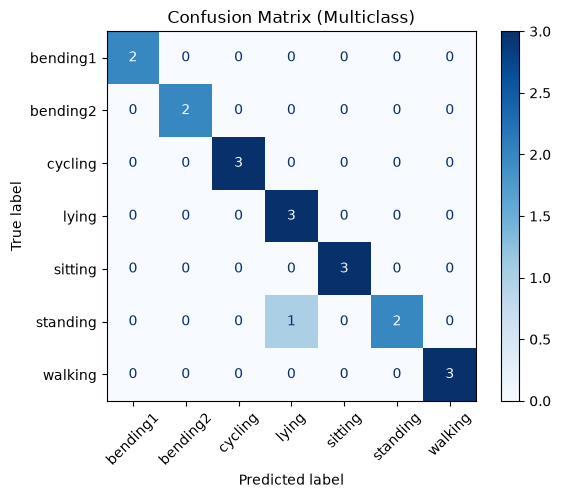

Multiclass AUC (OvR): 1.000


In [40]:
import numpy as np
import pandas as pd
import warnings
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, roc_auc_score
import matplotlib.pyplot as plt

# Ignore warnings to keep the output clean
warnings.filterwarnings("ignore")

# Use 5-fold stratified CV
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# Encode string labels to numbers (0 to 6)
le = LabelEncoder()
y_multi = le.fit_transform(y_train.values)

results_multi = {}

print("Starting 2(c)i Cross-Validation...")

for l in range(1, 21):
    # Build features for this l
    X = make_features(l)
    
    # Standardize features (important for L1 penalty)
    scaler = StandardScaler().fit(X)
    X_scaled = scaler.transform(X)
    
    # L1-penalized multinomial logistic regression
    # Use saga solver for multinomial L1, and increase max_iter to 5000
    clf = LogisticRegression(l1_ratio=1.0, solver='saga', max_iter=5000)
    
    # Try different C values (smaller C = stronger regularization)
    param_grid = {'C': [0.001, 0.01, 0.1, 1.0, 10.0]}
    
    # GridSearchCV will try each C and do 5-fold CV
    grid = GridSearchCV(clf, param_grid, cv=skf, scoring='accuracy')
    grid.fit(X_scaled, y_multi)
    
    # Save the results for this l
    results_multi[l] = {
        'best_C': grid.best_params_['C'],
        'best_score': grid.best_score_,
        'best_model': grid.best_estimator_
    }
    
    print(f"l={l:2d}, best C={grid.best_params_['C']:<6}, CV accuracy={grid.best_score_:.3f}")

# Find the best l
best_l_multi = max(results_multi, key=lambda l: results_multi[l]['best_score'])
best_C_multi = results_multi[best_l_multi]['best_C']
print(f"\nBest l: {best_l_multi}, best C: {best_C_multi}, CV accuracy: {results_multi[best_l_multi]['best_score']:.3f}")

# Test the best model on the test set

# Build test features with the best l
X_test_final = make_features_from_files(test_files, best_l_multi)
# Get true test labels and encode them
y_test_multi = le.transform([f.split("/")[-2] for f in test_files])

# Scale test data using the scaler fitted on the full training data
X_train_best = make_features(best_l_multi)
scaler_best = StandardScaler().fit(X_train_best)
X_test_scaled = scaler_best.transform(X_test_final)

# Train the best model on the full training set
best_model = LogisticRegression(l1_ratio=1.0, C=best_C_multi, solver='saga', max_iter=5000)
best_model.fit(scaler_best.transform(X_train_best), y_multi)

# Predict on test set
y_test_pred = best_model.predict(X_test_scaled)
test_error = 1 - accuracy_score(y_test_multi, y_test_pred)
print(f"\nTest error: {test_error:.4f}")

# Multiclass confusion matrix
cm = confusion_matrix(y_test_multi, y_test_pred, labels=best_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix (Multiclass)")
plt.show()

# Multiclass AUC (One-vs-Rest)
y_test_prob = best_model.predict_proba(X_test_scaled)
auc_multi = roc_auc_score(y_test_multi, y_test_prob, multi_class='ovr')
print(f"Multiclass AUC (OvR): {auc_multi:.3f}")

In [41]:
## ii

Running Naive Bayes Cross-Validation for l=1 to 20...
l= 1, GNB acc=0.840, MNB acc=0.566
l= 2, GNB acc=0.829, MNB acc=0.652
l= 3, GNB acc=0.725, MNB acc=0.622
l= 4, GNB acc=0.740, MNB acc=0.623
l= 5, GNB acc=0.725, MNB acc=0.710
l= 6, GNB acc=0.741, MNB acc=0.652
l= 7, GNB acc=0.740, MNB acc=0.665
l= 8, GNB acc=0.695, MNB acc=0.679
l= 9, GNB acc=0.699, MNB acc=0.695
l=10, GNB acc=0.727, MNB acc=0.695
l=11, GNB acc=0.653, MNB acc=0.666
l=12, GNB acc=0.656, MNB acc=0.695
l=13, GNB acc=0.729, MNB acc=0.679
l=14, GNB acc=0.624, MNB acc=0.680
l=15, GNB acc=0.596, MNB acc=0.665
l=16, GNB acc=0.611, MNB acc=0.665
l=17, GNB acc=0.624, MNB acc=0.666
l=18, GNB acc=0.567, MNB acc=0.679
l=19, GNB acc=0.566, MNB acc=0.651
l=20, GNB acc=0.581, MNB acc=0.666

Best l for Gaussian NB: 1 (CV acc: 0.840)
Best l for Multinomial NB: 5 (CV acc: 0.710)

Gaussian NB Test Accuracy: 0.8947
Multinomial NB Test Accuracy: 0.7895


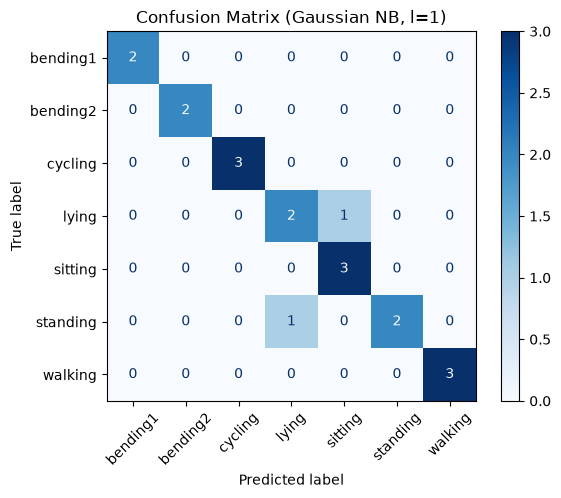

In [42]:
import numpy as np
import warnings
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Ignore warnings
warnings.filterwarnings("ignore")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

results_gnb = {}
results_mnb = {}

print("Running Naive Bayes Cross-Validation for l=1 to 20...")

for l in range(1, 21):
    # Build features
    X = make_features(l)
    
    # 1. Gaussian NB (uses StandardScaler)
    scaler_std = StandardScaler().fit(X)
    X_std = scaler_std.transform(X)
    gnb = GaussianNB()
    score_gnb = cross_val_score(gnb, X_std, y_multi, cv=skf, scoring='accuracy').mean()
    results_gnb[l] = score_gnb
    
    # 2. Multinomial NB (requires non-negative features, so use MinMaxScaler)
    scaler_mm = MinMaxScaler().fit(X)
    X_mm = scaler_mm.transform(X)
    mnb = MultinomialNB()
    score_mnb = cross_val_score(mnb, X_mm, y_multi, cv=skf, scoring='accuracy').mean()
    results_mnb[l] = score_mnb
    
    print(f"l={l:2d}, GNB acc={score_gnb:.3f}, MNB acc={score_mnb:.3f}")

# Find best l for each
best_l_gnb = max(results_gnb, key=results_gnb.get)
best_l_mnb = max(results_mnb, key=results_mnb.get)

print(f"\nBest l for Gaussian NB: {best_l_gnb} (CV acc: {results_gnb[best_l_gnb]:.3f})")
print(f"Best l for Multinomial NB: {best_l_mnb} (CV acc: {results_mnb[best_l_mnb]:.3f})")

# Test on test set for Gaussian NB
X_test_final_gnb = make_features_from_files(test_files, best_l_gnb)
y_test_multi = le.transform([f.split("/")[-2] for f in test_files])
X_train_best_gnb = make_features(best_l_gnb)
scaler_best_gnb = StandardScaler().fit(X_train_best_gnb)
X_test_scaled_gnb = scaler_best_gnb.transform(X_test_final_gnb)

gnb_final = GaussianNB().fit(scaler_best_gnb.transform(X_train_best_gnb), y_multi)
y_test_pred_gnb = gnb_final.predict(X_test_scaled_gnb)
test_acc_gnb = accuracy_score(y_test_multi, y_test_pred_gnb)

# Test on test set for Multinomial NB
X_test_final_mnb = make_features_from_files(test_files, best_l_mnb)
X_train_best_mnb = make_features(best_l_mnb)
scaler_best_mnb = MinMaxScaler().fit(X_train_best_mnb)
X_test_scaled_mnb = scaler_best_mnb.transform(X_test_final_mnb)

mnb_final = MultinomialNB().fit(scaler_best_mnb.transform(X_train_best_mnb), y_multi)
y_test_pred_mnb = mnb_final.predict(X_test_scaled_mnb)
test_acc_mnb = accuracy_score(y_test_multi, y_test_pred_mnb)

print(f"\nGaussian NB Test Accuracy: {test_acc_gnb:.4f}")
print(f"Multinomial NB Test Accuracy: {test_acc_mnb:.4f}")

# Plot confusion matrix for the better one (usually Gaussian)
cm_gnb = confusion_matrix(y_test_multi, y_test_pred_gnb, labels=gnb_final.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_gnb, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title(f"Confusion Matrix (Gaussian NB, l={best_l_gnb})")
plt.show()

In [43]:
## iii

In [44]:
# In this multi-class problem, the L1-penalized multinomial regression model performed the best
# because it had the highest test accuracy (about 0.947), compared to 0.895 for Gaussian Naïve Bayes and 0.789 
# for Multinomial Naïve Bayes. Gaussian NB did okay, but it assumes all features are completely independent, 
# which ignores the relationships between time series features. 
# Multinomial NB did the worst because it is designed for non-negative discrete counts, 
# which doesn't fit our continuous time-domain features that can have negative values. Therefore, the L1-penalized multinomial
# regression is the best method for this problem.

In [45]:
# 3

In [46]:
## ISLR 4.8.3

In [47]:
# ## Proof that QDA with p=1 is Quadratic, When p=1, the probability density function for a normal distribution of the k-th class is: 
# f_k(x) = (1 / (√(2π) σ_k)) * exp( - (x - μ_k)^2 / (2σ_k^2) ). According to the Bayes classifier, we assign the 
# sample to the class with the highest posterior probability. To make the math easier, we take the log and ignore 
# the constant terms that don't depend on k. The discriminant function for the k-th class becomes:
#δ_k(x) = log(π_k) - log(σ_k) - (x - μ_k)^2 / (2σ_k^2). Expanding the squared term, we get:
# δ_k(x) = log(π_k) - log(σ_k) - x^2 / (2σ_k^2) + (x * μ_k) / σ_k^2 - μ_k^2 / (2σ_k^2).  The decision boundary is where the 
# discriminant functions for two classes (let's say j and k) are equal, meaning δ_j(x) = δ_k(x). Subtracting the two 
# sides and grouping the x^2, x, and constant terms, we get:
# ( 1 / (2σ_k^2) - 1 / (2σ_j^2) ) * x^2 + ( μ_j / σ_j^2 - μ_k / σ_k^2 ) * x + 
# ( log(π_j / π_k) - log(σ_j / σ_k) - μ_j^2 / (2σ_j^2) + μ_k^2 / (2σ_k^2) ) = 0
# Because we don't assume all variances are equal, usually σ_j^2 not equal σ_k^2. 
# Therefore, the coefficient in front of x^2, which is ( 1 / (2σ_k^2) - 1 / (2σ_j^2) ), is not zero.
# Since the equation has an x^2 term, it is a quadratic equation of the form ax^2 + bx + c = 0. 
# This means the decision boundary of the Bayes classifier is not a straight line (not linear), but a curve (quadratic).

In [48]:
# 4

In [49]:
## ISLR 4.8.7

In [50]:
# Given prior probabilities P(Yes) = 0.8 and P(No) = 0.2, means μ_Yes = 10 and μ_No = 0, common variance σ^2 = 36, and new observation X = 4.
# Using Bayes' theorem to calculate P(Yes | X=4):
# Numerator for Yes = exp( -(4 - 10)^2 / (2 * 36) ) * 0.8 = exp(-0.5) * 0.8, which is approximately 0.6065 * 0.8 = 0.4852.
# Denominator part for No = exp( -(4 - 0)^2 / (2 * 36) ) * 0.2 = exp(-0.2222) * 0.2, which is approximately 0.8007 * 0.2 = 0.1601.
# Total denominator = 0.4852 + 0.1601 = 0.6453.
# P(Yes | X=4) = 0.4852 / 0.6453, which is approximately 0.7518.
# So, the probability that the company will issue a dividend this year, given that its percentage profit was 4 last year, 
# is approximately 75.18%.